In [27]:
import json
from collections import Counter
with open('201401.json', 'r', encoding="utf8") as file:
    data_201401 = json.load(file)
with open('202401.json', 'r', encoding="utf8") as file:
    data_202401 = json.load(file)
with open('201402.json', 'r', encoding="utf8") as file:
    data_201402 = json.load(file)
with open('202402.json', 'r', encoding="utf8") as file:
    data_202402 = json.load(file)
with open('201409.json', 'r', encoding="utf8") as file:
    data_201409 = json.load(file)
with open('202409.json', 'r', encoding="utf8") as file:
    data_202409 = json.load(file)

In [28]:
# 201401
journal_cleans_201401 = [valeur["journal_clean"] for valeur in data_201401.values()]
print("Nombre de journaux uniques sortie en janvier 2014 :", len(set(journal_cleans_201401)))
print ()
for journal, count in Counter(journal_cleans_201401).items():
    print("  Le journal", journal, "a sorti", count, "articles en janvier 2014")
print ()
# 202401
journal_cleans_202401 = [valeur["journal_clean"] for valeur in data_202401.values()]
print("Nombre de journaux uniques sortie en janvier 2024 :", len(set(journal_cleans_202401)))
print ()
for journal, count in Counter(journal_cleans_202401).items():
    print("  Le journal", journal, "a sorti", count, "articles en janvier 2024")
print ()
# 201402
journal_cleans_201402 = [valeur["journal_clean"] for valeur in data_201402.values()]
print("Nombre de journaux uniques sortie en février 2014 :", len(set(journal_cleans_201402)))
print ()
for journal, count in Counter(journal_cleans_201402).items():
    print("  Le journal", journal, "a sorti", count, "articles en février 2014")
print ()
# 202402
journal_cleans_202402 = [valeur["journal_clean"] for valeur in data_202402.values()]
print("Nombre de journaux uniques sortie en février 2024 :", len(set(journal_cleans_202402)))
print ()
for journal, count in Counter(journal_cleans_202402).items():
    print("  Le journal", journal, "a sorti", count, "articles en février 2024")
    
print ()
# 201409
journal_cleans_201409 = [valeur["journal_clean"] for valeur in data_201409.values()]
print("Nombre de journaux uniques sortie en septembre 2014 :", len(set(journal_cleans_201409)))
print ()
for journal, count in Counter(journal_cleans_201409).items():
    print("  Le journal", journal, "a sorti", count, "articles en septembre 2014")
print ()
# 202409
journal_cleans_202409 = [valeur["journal_clean"] for valeur in data_202409.values()]
print("Nombre de journaux uniques sortie en septembre 2024 :", len(set(journal_cleans_202409)))
print ()
for journal, count in Counter(journal_cleans_202409).items():
    print("  Le journal", journal, "a sorti", count, "articles en septembre 2024")
    
print ()
journal_tot = len(data_201401) + len(data_202401) + len(data_201402) + len(data_202402) + len(data_201409) + len(data_202409)
print("nombre de journaux totals : ", journal_tot)

Nombre de journaux uniques sortie en janvier 2014 : 10

  Le journal Aujourd'hui en France a sorti 4083 articles en janvier 2014
  Le journal Le Monde a sorti 2722 articles en janvier 2014
  Le journal Libération a sorti 2113 articles en janvier 2014
  Le journal La Tribune a sorti 797 articles en janvier 2014
  Le journal l'Humanité a sorti 1828 articles en janvier 2014
  Le journal Le Figaro a sorti 3906 articles en janvier 2014
  Le journal La Correspondance économique a sorti 966 articles en janvier 2014
  Le journal La Croix a sorti 2022 articles en janvier 2014
  Le journal L'AGEFI Quotidien a sorti 1438 articles en janvier 2014
  Le journal Les Echos a sorti 3356 articles en janvier 2014

Nombre de journaux uniques sortie en janvier 2024 : 11

  Le journal Le Figaro a sorti 3093 articles en janvier 2024
  Le journal l'Humanité a sorti 775 articles en janvier 2024
  Le journal La Croix a sorti 1562 articles en janvier 2024
  Le journal Les Echos a sorti 2119 articles en janvier 2

In [31]:
j_201401 = set(article["journal_clean"] for article in data_201401.values())
j_202401 = set(article["journal_clean"] for article in data_202401.values())
j_201402 = set(article["journal_clean"] for article in data_201402.values())
j_202402 = set(article["journal_clean"] for article in data_202402.values())
j_201409 = set(article["journal_clean"] for article in data_201409.values())
j_202409 = set(article["journal_clean"] for article in data_202409.values())
journaux = j_201401 & j_202401 & j_201402 & j_202402 & j_201409 & j_202409
print(journaux)

{'Les Echos', 'Libération', "Aujourd'hui en France", 'La Croix', 'Le Figaro', 'La Correspondance économique', "L'AGEFI Quotidien", 'Le Monde', 'La Tribune'}


In [33]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('french'))
stop_words.update([
    "plus", "cette", "comme", "être", "fait", "tout", "tous", "toute", "toutes",
    "aussi", "deux", "depuis", "après", "avant", "ans", "hier", "encore",
    "peu", "très", "bien", "où", "si", "ainsi", "alors", "car", "donc",
    "janvier", "février", "septembre", "2013", "2023"
])

from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
def get_textes(data):
    return [article.get("texte", "") for article in data.values()]
corpus_201401 = get_textes(data_201401)
corpus_202401 = get_textes(data_202401)
corpus_201402 = get_textes(data_201402)
corpus_202402 = get_textes(data_202402)
corpus_201409 = get_textes(data_201409)
corpus_202409 = get_textes(data_202409)

vec = TfidfVectorizer(stop_words=list(stop_words))
X = vec.fit_transform(corpus_201401 + corpus_202401 + corpus_201402 + corpus_202402 + corpus_201409 + corpus_202409)
n1 = len(corpus_201401)
n2 = n1 + len(corpus_202401)
n3 = n2 + len(corpus_201402)
n4 = n3 + len(corpus_202402)
n5 = n4 + len(corpus_201409)
n6 = n5 + len(corpus_202409)
scores_201401 = np.asarray(X[:n1].mean(axis=0)).ravel()
scores_202401 = np.asarray(X[n1:n2].mean(axis=0)).ravel()
scores_201402 = np.asarray(X[n2:n3].mean(axis=0)).ravel()
scores_202402 = np.asarray(X[n3:n4].mean(axis=0)).ravel()
scores_201409 = np.asarray(X[n4:n5].mean(axis=0)).ravel()
scores_202409 = np.asarray(X[n5:n6].mean(axis=0)).ravel()
print()

seuil = 0.010

print()
print("15 termes janvier 2014 (moyenne TF-IDF) :")
for term, score in sorted(zip(terms, scores_201401), key=lambda x: x[1], reverse=True)[:15]:
    if score >= seuil:
        print(f"  {term:20s}  {score:.4f}")
print(" 15 termes janvier 2024 (moyenne TF-IDF) :")
print()
for term, score in sorted(zip(terms, scores_202401), key=lambda x: x[1], reverse=True)[:15]:
    if score >= seuil:
        print(f"  {term:20s}  {score:.4f}")
print(" 15 termes février 2014 (moyenne TF-IDF) :")
print()
for term, score in sorted(zip(terms, scores_201402), key=lambda x: x[1], reverse=True)[:15]:
    if score >= seuil:
        print(f"  {term:20s}  {score:.4f}")
print("15 termes février 2024 (moyenne TF-IDF) :")
print()
for term, score in sorted(zip(terms, scores_202402), key=lambda x: x[1], reverse=True)[:15]:
    if score >= seuil:
        print(f"  {term:20s}  {score:.4f}")
print(" 15 termes septembre 2014 (moyenne TF-IDF) :")
print()
for term, score in sorted(zip(terms, scores_201409), key=lambda x: x[1], reverse=True)[:15]:
    if score >= seuil:
        print(f"  {term:20s}  {score:.4f}")
print(" 15 termes septembre 2024 (moyenne TF-IDF) :")
print()
for term, score in sorted(zip(terms, scores_202409), key=lambda x: x[1], reverse=True)[:15]:
    if score >= seuil:
        print(f"  {term:20s}  {score:.4f}")

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/faycalsalhi/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!




15 termes janvier 2014 (moyenne TF-IDF) :
  framtidspartiet       0.0132
  europôle              0.0116
  millfields            0.0106
  préservions           0.0104
  million               0.0101
 15 termes janvier 2024 (moyenne TF-IDF) :

  framtidspartiet       0.0157
  europôle              0.0120
  minispace             0.0110
  entraîneront          0.0109
  2023à15h31etmisàjourà17h23  0.0107
  faimjusqu             0.0105
  payne                 0.0104
  sanoetre              0.0103
  anné                  0.0101
  2021séverine          0.0100
 15 termes février 2014 (moyenne TF-IDF) :

  europôle              0.0138
  framtidspartiet       0.0132
  million               0.0109
  millfields            0.0106
  grouman               0.0101
15 termes février 2024 (moyenne TF-IDF) :

  europôle              0.0164
  framtidspartiet       0.0156
  millfields            0.0121
  entraîneront          0.0109
  grouman               0.0109
  faimjusqu             0.0106
  sanoetre   

In [34]:
#lda 
#ia 
import re

!pip install gensim

from gensim import corpora
from gensim.models import LdaModel

def tokeniser_lda(texte):
    return [mot for mot in re.findall(r"[a-zA-ZÀ-ÿ-]+", texte.lower()) if mot not in stop_words and len(mot) > 2]
    
# 201401
textes_201401 = [tokeniser_lda(article.get("texte", "")) for article in data_201401.values()]
dico_201401 = corpora.Dictionary(textes_201401)
corpus_lda_201401 = [dico_201401.doc2bow(texte) for texte in textes_201401]
lda_201401 = LdaModel(corpus_lda_201401, num_topics=10, id2word=dico_201401, passes=5, random_state=42)

# 202401
textes_202401 = [tokeniser_lda(article.get("texte", "")) for article in data_202401.values()]
dico_202401 = corpora.Dictionary(textes_202401)
corpus_lda_202401 = [dico_202401.doc2bow(texte) for texte in textes_202401]
lda_202401 = LdaModel(corpus_lda_202401, num_topics=10, id2word=dico_202401, passes=5, random_state=42)

# 201402
textes_201402 = [tokeniser_lda(article.get("texte", "")) for article in data_201402.values()]
dico_201402 = corpora.Dictionary(textes_201402)
corpus_lda_201402 = [dico_201402.doc2bow(texte) for texte in textes_201402]
lda_201402 = LdaModel(corpus_lda_201402, num_topics=10, id2word=dico_201402, passes=5, random_state=42)

# 202402
textes_202402 = [tokeniser_lda(article.get("texte", "")) for article in data_202402.values()]
dico_202402 = corpora.Dictionary(textes_202402)
corpus_lda_202402 = [dico_202402.doc2bow(texte) for texte in textes_202402]
lda_202402 = LdaModel(corpus_lda_202402, num_topics=10, id2word=dico_202402, passes=5, random_state=42)

# 201409
textes_201409 = [tokeniser_lda(article.get("texte", "")) for article in data_201409.values()]
dico_201409 = corpora.Dictionary(textes_201409)
corpus_lda_201409 = [dico_201409.doc2bow(texte) for texte in textes_201409]
lda_201409 = LdaModel(corpus_lda_201409, num_topics=10, id2word=dico_201409, passes=5, random_state=42)

# 202409
textes_202409 = [tokeniser_lda(article.get("texte", "")) for article in data_202409.values()]
dico_202409 = corpora.Dictionary(textes_202409)
corpus_lda_202409 = [dico_202409.doc2bow(texte) for texte in textes_202409]
lda_202409 = LdaModel(corpus_lda_202409, num_topics=10, id2word=dico_202409, passes=5, random_state=42)

print("Topics janvier 2014 :")
for i, topic in lda_201401.print_topics():
    print(f"  Topic {i} : {topic}")
print("\nTopics janvier 2024 :")
for i, topic in lda_202401.print_topics():
    print(f"  Topic {i} : {topic}")
print("\nTopics février 2014 :")
for i, topic in lda_201402.print_topics():
    print(f"  Topic {i} : {topic}")
print("\nTopics février 2024 :")
for i, topic in lda_202402.print_topics():
    print(f"  Topic {i} : {topic}")
print("\nTopics septembre 2014 :")
for i, topic in lda_201409.print_topics():
    print(f"  Topic {i} : {topic}")
print("\nTopics septembre 2024 :")
for i, topic in lda_202409.print_topics():
    print(f"  Topic {i} : {topic}")

Topics janvier 2014 :
  Topic 0 : 0.021*"prix" + 0.021*"terrain" + 0.020*"part" + 0.016*"bon" + 0.013*"coup" + 0.011*"attelé" + 0.011*"course" + 0.009*"trio" + 0.008*"vincennes" + 0.007*"performance"
  Topic 1 : 0.021*"euros" + 0.012*"millions" + 0.010*"groupe" + 0.008*"capital" + 0.008*"fonds" + 0.007*"salariés" + 0.007*"banque" + 0.006*"entreprise" + 0.005*"société" + 0.005*"banques"
  Topic 2 : 0.004*"leurs" + 0.004*"faire" + 0.004*"entre" + 0.004*"autres" + 0.004*"peut" + 0.004*"sans" + 0.003*"personnes" + 0.003*"moins" + 0.003*"cas" + 0.003*"cela"
  Topic 3 : 0.026*"directeur" + 0.019*"général" + 0.013*"président" + 0.010*"ancien" + 0.010*"paris" + 0.010*"conseil" + 0.009*"groupe" + 0.008*"mme" + 0.008*"france" + 0.008*"direction"
  Topic 4 : 0.009*"entreprises" + 0.006*"emploi" + 0.006*"taux" + 0.006*"milliards" + 0.006*"france" + 0.006*"pays" + 0.005*"croissance" + 0.005*"chômage" + 0.005*"baisse" + 0.004*"économie"
  Topic 5 : 0.007*"pays" + 0.006*"président" + 0.006*"ministre"

In [35]:
#ia
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
# Extraire les vecteurs de topics (distribution sur le vocabulaire)
def get_topic_vectors(model, num_topics, num_words=100):
    vecteurs = []
    for i in range(num_topics):
        vecteur = dict(model.show_topic(i, topn=num_words))
        vecteurs.append(vecteur)
    return vecteurs
def vectoriser(topic_dict, vocab):
    return np.array([topic_dict.get(mot, 0) for mot in vocab])

def comparer(lda_a, lda_b, label_a, label_b):
    # Aligner les vocabulaires
    vocab = set()
    for i in range(10):
        vocab.update(dict(lda_a.show_topic(i, topn=100)).keys())
        vocab.update(dict(lda_b.show_topic(i, topn=100)).keys())
    vocab = list(vocab)
    topics_a = [vectoriser(dict(lda_a.show_topic(i, topn=100)), vocab) for i in range(10)]
    topics_b = [vectoriser(dict(lda_b.show_topic(i, topn=100)), vocab) for i in range(10)]
    # Matrice de similarité
    matrice = cosine_similarity(topics_a, topics_b)
    print(f"Similarité cosinus entre topics {label_a} (lignes) et {label_b} (colonnes) :")
    print("        " + "  ".join([f"T{i}{label_b}" for i in range(10)]))
    for i, ligne in enumerate(matrice):
        print(f"T{i}{label_a}  " + "  ".join([f"{score:.2f}" for score in ligne]))
    print(f"\nMeilleurs matchs (potentiels marronniers) {label_a} ↔ {label_b} :")
    for i in range(10):
        j = np.argmax(matrice[i])
        print(f"  Topic {i} {label_a} ↔ Topic {j} {label_b}  similarité={matrice[i][j]:.2f}")
    print()

comparer(lda_201401, lda_202401, "01-14", "01-24")
comparer(lda_201402, lda_202402, "02-14", "02-24")
comparer(lda_201409, lda_202409, "09-14", "09-24")

Similarité cosinus entre topics 01-14 (lignes) et 01-24 (colonnes) :
        T001-24  T101-24  T201-24  T301-24  T401-24  T501-24  T601-24  T701-24  T801-24  T901-24
T001-14  0.01  0.00  0.06  0.12  0.02  0.04  0.05  0.01  0.00  0.01
T101-14  0.10  0.08  0.12  0.71  0.06  0.04  0.11  0.00  0.11  0.35
T201-14  0.40  0.15  0.30  0.21  0.66  0.13  0.21  0.07  0.07  0.42
T301-14  0.16  0.06  0.12  0.08  0.04  0.06  0.06  0.01  0.85  0.08
T401-14  0.34  0.16  0.16  0.48  0.19  0.12  0.62  0.01  0.13  0.32
T501-14  0.67  0.39  0.20  0.17  0.27  0.14  0.45  0.01  0.21  0.23
T601-14  0.28  0.16  0.38  0.18  0.33  0.15  0.20  0.01  0.11  0.26
T701-14  0.28  0.13  0.63  0.14  0.80  0.11  0.17  0.01  0.08  0.24
T801-14  0.16  0.15  0.24  0.70  0.15  0.11  0.41  0.01  0.10  0.38
T901-14  0.33  0.05  0.17  0.05  0.23  0.07  0.11  0.00  0.14  0.10

Meilleurs matchs (potentiels marronniers) 01-14 ↔ 01-24 :
  Topic 0 01-14 ↔ Topic 3 01-24  similarité=0.12
  Topic 1 01-14 ↔ Topic 3 01-24  similarité=0.

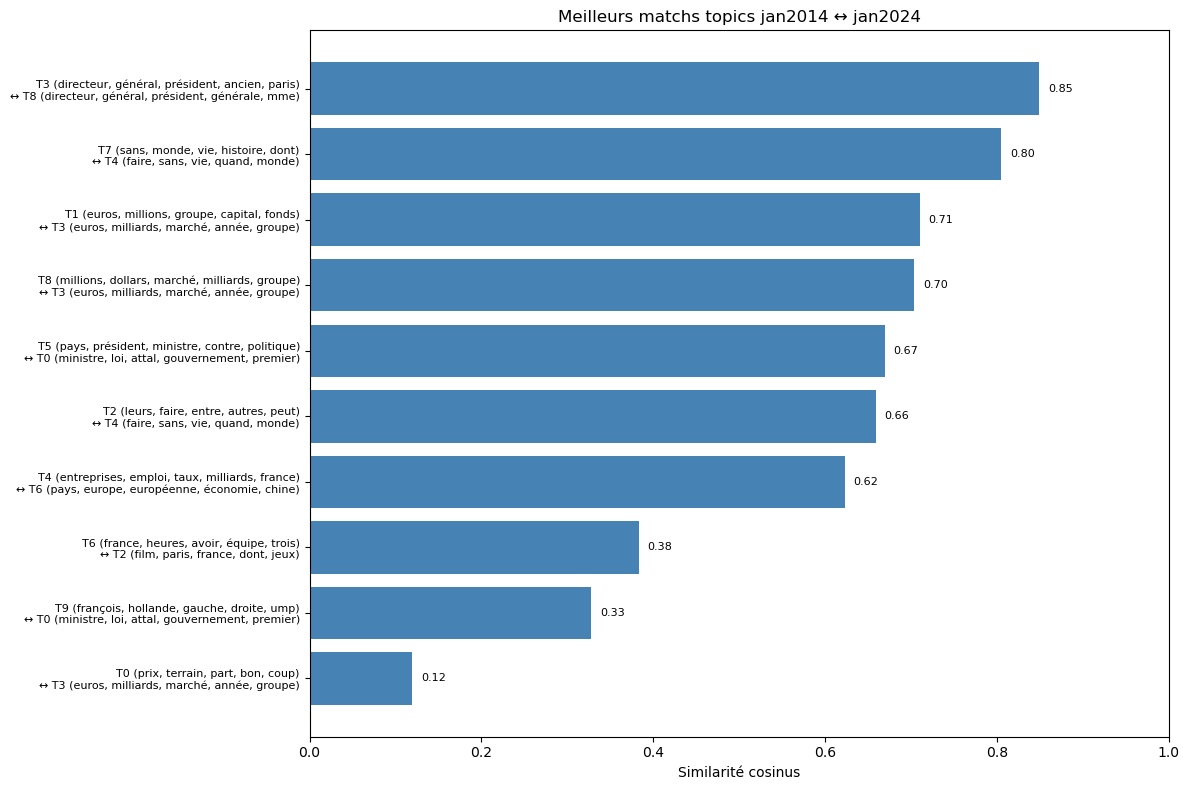

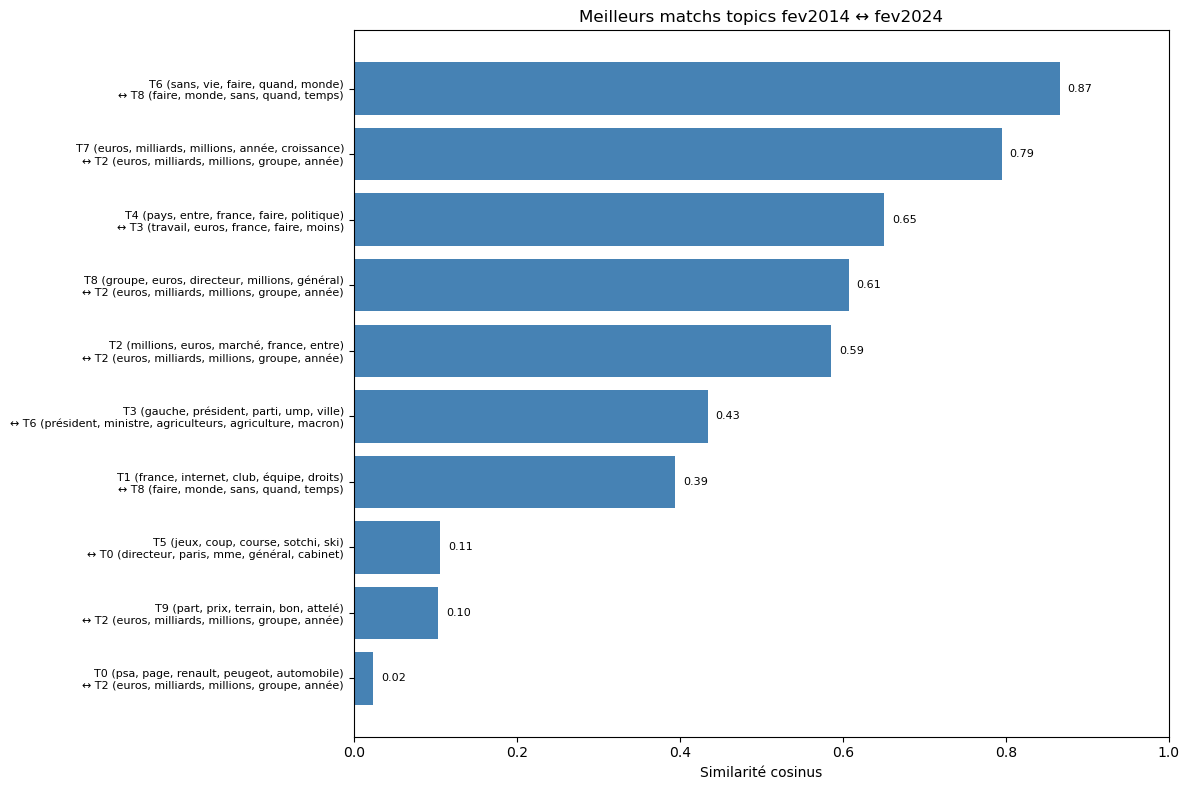

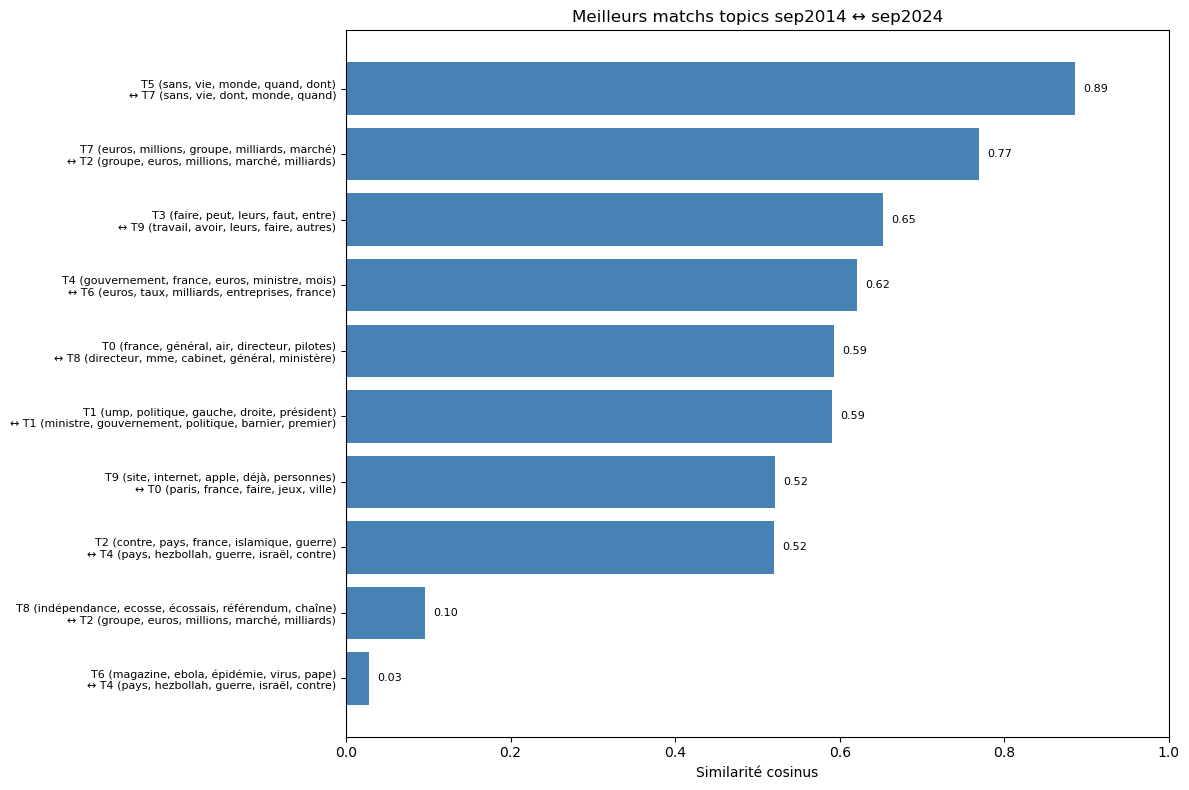

In [44]:
#ia
import matplotlib.pyplot as pyplot
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

def vectoriser(topic_dict, vocab):
    return np.array([topic_dict.get(mot, 0) for mot in vocab])

def visu_matchs(lda_a, lda_b, label_a, label_b):
    vocab = set()
    for i in range(10):
        vocab.update(dict(lda_a.show_topic(i, topn=100)).keys())
        vocab.update(dict(lda_b.show_topic(i, topn=100)).keys())
    vocab = list(vocab)
    topics_a = [vectoriser(dict(lda_a.show_topic(i, topn=100)), vocab) for i in range(10)]
    topics_b = [vectoriser(dict(lda_b.show_topic(i, topn=100)), vocab) for i in range(10)]
    matrice = cosine_similarity(topics_a, topics_b)
    # meilleurs matchs
    labels = []
    scores = []
    for i in range(10):
        j = np.argmax(matrice[i])
        sim = matrice[i][j]
        mots_a = ", ".join([mot for mot, _ in lda_a.show_topic(i, topn=5)])
        mots_b = ", ".join([mot for mot, _ in lda_b.show_topic(j, topn=5)])
        labels.append(f"T{i} ({mots_a})\n↔ T{j} ({mots_b})")
        scores.append(sim)
    # tri par similarité décroissante
    ordre = np.argsort(scores)[::-1]
    labels = [labels[k] for k in ordre]
    scores = [scores[k] for k in ordre]
    pyplot.figure(figsize=(12, 8))
    barres = pyplot.barh(range(len(scores)), scores, color="steelblue")
    pyplot.yticks(range(len(scores)), labels, fontsize=8)
    pyplot.xlabel("Similarité cosinus")
    pyplot.title("Meilleurs matchs topics " + label_a + " ↔ " + label_b)
    pyplot.xlim(0, 1)
    for barre, score in zip(barres, scores):
        pyplot.text(score + 0.01, barre.get_y() + barre.get_height() / 2, f"{score:.2f}", va="center", fontsize=8)
    pyplot.gca().invert_yaxis()
    pyplot.tight_layout()
    pyplot.savefig("matchs_" + label_a + "_" + label_b + ".png")
    pyplot.show()

visu_matchs(lda_201401, lda_202401, "jan2014", "jan2024")
visu_matchs(lda_201402, lda_202402, "fev2014", "fev2024")
visu_matchs(lda_201409, lda_202409, "sep2014", "sep2024")